# Part 1 — Network Data and Exploratory Analysis

This notebook introduces the network used throughout the project and describes its structure before centrality analysis. It uses Zachary's Karate Club graph by default: 34 club members connected when they socialised outside the club.

## Objectives

- Load a social network from a reproducible source.
- Measure its size, density, connectivity, distances, and clustering.
- Visualise the network and its degree distribution.

The reusable functions live in `src/`, keeping later notebooks concise and consistent.

In [1]:
from pathlib import Path
import sys

# Find the project root whether Jupyter was started here or from notebooks/.
PROJECT_ROOT = next(parent for parent in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (parent / 'src').is_dir())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import pandas as pd

from src.data_loader import load_graph, network_summary
from src.visualization import graph_layout, plot_degree_distribution, plot_network

plt.rcParams['figure.dpi'] = 110
pd.set_option('display.precision', 4)

## 1. Load the data

`karate` is bundled with NetworkX, so everyone can reproduce this result. To use an edge-list or `.mtx` dataset later, place it in `data/` and replace `DATA_SOURCE` with its path.

In [2]:
DATA_SOURCE = 'karate'  # e.g. '../data/your_network.txt'
G = load_graph(DATA_SOURCE)
print(G)
print(f'Undirected: {not G.is_directed()}')

Graph named "Zachary's Karate Club" with 34 nodes and 78 edges
Undirected: True


## 2. Network overview

The spring layout places strongly connected members closer together. It is a visual aid, not a geographic map. A fixed seed makes the plot reproducible.

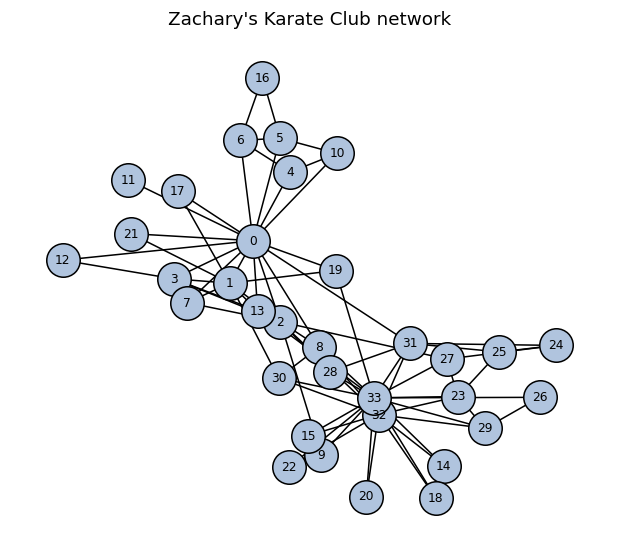

In [3]:
pos = graph_layout(G, seed=42)
plot_network(G, pos, title="Zachary's Karate Club network")
plt.show()

## 3. Basic network statistics

- **Density:** fraction of possible ties that are observed.
- **Diameter:** longest shortest path in the largest connected component.
- **Average shortest path:** typical number of steps between connected members.
- **Clustering / transitivity:** tendency for a member's contacts to also know one another.

For a disconnected graph, distance-based statistics are calculated on its largest connected component.

In [4]:
stats = network_summary(G)
pd.Series(stats, name='value').to_frame()

,value
Nodes,34.0000
Edges,78.0000
Density,0.1390
Average degree,4.5882
Connected components,1.0000
Largest component nodes,34.0000
Diameter (largest component),5.0000
Average shortest path (largest component),2.4082
Average clustering,0.5706
Transitivity,0.2557


## 4. Degree distribution

A node's degree is its number of direct social ties. A right-skewed distribution means most members have few ties while a small number act as hubs.

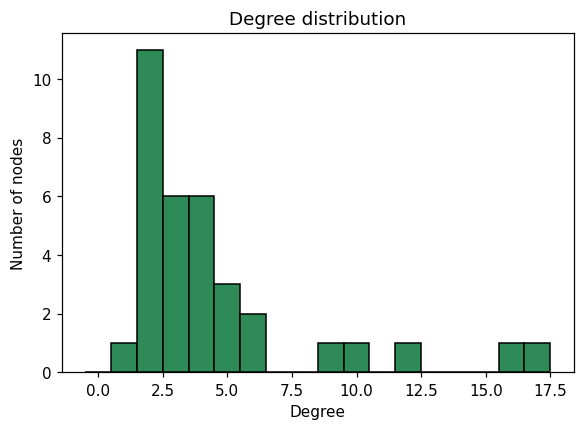

,node,degree
0,33,17
1,0,16
2,32,12
3,2,10
4,1,9
5,3,6
6,31,6
7,23,5
8,8,5
9,13,5


In [5]:
plot_degree_distribution(G)
plt.show()

degree_table = (
    pd.DataFrame(G.degree(), columns=['node', 'degree'])
    .sort_values('degree', ascending=False)
    .reset_index(drop=True)
)
degree_table.head(10)

## Findings

The Karate Club graph is sparse but connected, with short paths between members and substantial clustering. Its unequal degree distribution suggests that a few highly connected members may be especially important. Part 2 tests that idea using several centrality metrics rather than degree alone.

**Source:** Zachary, W. W. (1977), *An information flow model for conflict and fission in small groups*, *Journal of Anthropological Research*.